##This notebook includes my initial experiments to understand the gap in research in Mechanistic Interpretability

In [ ]:
!pip install sae-lens transformer-lens -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.1/145.1 kB 6.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.0/314.0 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.6/56.6 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.1/26.1 MB 89.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.6/204.6 kB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━

In [ ]:
import torch
from transformer_lens import HookedTransformer
from sae_lens import SAE

torch.set_grad_enabled(False)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


In [ ]:
from huggingface_hub import login
login(token="Enter your token Here")

## Load the model

In [ ]:
model = HookedTransformer.from_pretrained("gemma-2b", device=device)

/tmp/ipykernel_1643/1281311699.py:1: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("gemma-2b", device=device)


config.json:   0%|          | 0.00/627 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/13.5k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/164 [00:00<?, ?it/s]

... (2 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

Loaded pretrained model gemma-2b into HookedTransformer


In [ ]:
HOOK_NAME = "blocks.12.hook_resid_post"

sae, cfg_dict, sparsity = SAE.from_pretrained(
    release="gemma-2b-res-jb",
    sae_id=HOOK_NAME,
    device=device,
)

cfg.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

gemma_2b_blocks.12.hook_resid_post_16384(…): reconstructing file:   0%|          |  0.00B /  269MB            

gemma_2b_blocks.12.hook_resid_post_16384(…): downloading bytes:           |  0.00B            

gemma_2b_blocks.12.hook_resid_post_16384(…): reconstructing file:   0%|          |  0.00B / 65.6kB            

gemma_2b_blocks.12.hook_resid_post_16384(…): downloading bytes:           |  0.00B            

/tmp/ipykernel_1643/477552510.py:3: DeprecationWarning: Unpacking SAE objects is deprecated. SAE.from_pretrained() now returns only the SAE object. Use SAE.from_pretrained_with_cfg_and_sparsity() to get the config dict and sparsity as well.
  sae, cfg_dict, sparsity = SAE.from_pretrained(


## Used a classic senetence which contains all alphabets of the English language

In [ ]:
text = "The quick brown fox jumps over the lazy dog"
tokens = model.to_tokens(text)
str_tokens = model.to_str_tokens(tokens)
print(f"{tokens.shape[-1]} tokens")

10 tokens


## Ran the model and cache the residual stream at layer 12

In [ ]:
_, cache = model.run_with_cache(
    tokens,
    names_filter=lambda name: name == HOOK_NAME,
)
resid_acts = cache[HOOK_NAME]  # [batch, seq, d_model] check shape with sae-shape
print(resid_acts.shape)

torch.Size([1, 10, 2048])


## Encode through the SAE to get feature activations

In [ ]:
feature_acts = sae.encode(resid_acts).squeeze(0)  # [seq, n_features]
print(feature_acts.shape)

torch.Size([10, 16384])


## Inspect the most active features across the text

This is also the list you'll narrow down to when you get to patching, you can't patch all ~16k features against each other, so this top-N is your candidate set.

In [ ]:
N_TOP = 20
max_acts_per_feature = feature_acts.max(dim=0).values      # [n_features]
top_vals, top_idxs = max_acts_per_feature.topk(N_TOP)

for val, idx in zip(top_vals, top_idxs):
    print(f"Feature {idx.item():>6}  |  max activation {val.item():.3f}")

Feature   8731  |  max activation 63.095
Feature   5233  |  max activation 61.437
Feature  10841  |  max activation 61.386
Feature   3048  |  max activation 54.960
Feature  11597  |  max activation 33.276
Feature   1645  |  max activation 32.919
Feature   6099  |  max activation 25.377
Feature   6802  |  max activation 23.839
Feature   8618  |  max activation 23.289
Feature   2227  |  max activation 22.787
Feature   7650  |  max activation 22.088
Feature   8297  |  max activation 22.058
Feature   7254  |  max activation 21.864
Feature  14175  |  max activation 21.576
Feature  15051  |  max activation 21.334
Feature   4662  |  max activation 21.015
Feature   9210  |  max activation 20.857
Feature  13000  |  max activation 20.832
Feature   9653  |  max activation 20.752
Feature   8824  |  max activation 20.179


## Neuronpedia lookup for labeling features

In [ ]:
def neuronpedia_url(feature_idx, layer=12, sae_set="res-jb", model_name="gemma-2b"):
    return f"https://www.neuronpedia.org/{model_name}/{layer}-{sae_set}/{feature_idx}"

for idx in top_idxs:
    print(neuronpedia_url(idx.item()))

https://www.neuronpedia.org/gemma-2b/12-res-jb/8731
https://www.neuronpedia.org/gemma-2b/12-res-jb/5233
https://www.neuronpedia.org/gemma-2b/12-res-jb/10841
https://www.neuronpedia.org/gemma-2b/12-res-jb/3048
https://www.neuronpedia.org/gemma-2b/12-res-jb/11597
https://www.neuronpedia.org/gemma-2b/12-res-jb/1645
https://www.neuronpedia.org/gemma-2b/12-res-jb/6099
https://www.neuronpedia.org/gemma-2b/12-res-jb/6802
https://www.neuronpedia.org/gemma-2b/12-res-jb/8618
https://www.neuronpedia.org/gemma-2b/12-res-jb/2227
https://www.neuronpedia.org/gemma-2b/12-res-jb/7650
https://www.neuronpedia.org/gemma-2b/12-res-jb/8297
https://www.neuronpedia.org/gemma-2b/12-res-jb/7254
https://www.neuronpedia.org/gemma-2b/12-res-jb/14175
https://www.neuronpedia.org/gemma-2b/12-res-jb/15051
https://www.neuronpedia.org/gemma-2b/12-res-jb/4662
https://www.neuronpedia.org/gemma-2b/12-res-jb/9210
https://www.neuronpedia.org/gemma-2b/12-res-jb/13000
https://www.neuronpedia.org/gemma-2b/12-res-jb/9653
https:/

In [ ]:
EARLY_LAYER = 6
EARLY_HOOK = f"blocks.{EARLY_LAYER}.hook_resid_post"
LATE_HOOK = HOOK_NAME    # from your setup cells: "blocks.12.hook_resid_post"
LATE_LAYER = 12

sae_early, _, _ = SAE.from_pretrained(
    release="gemma-2b-res-jb",
    sae_id=EARLY_HOOK,
    device=device,
)

cfg.json:   0%|          | 0.00/2.18k [00:00<?, ?B/s]

gemma_2b_blocks.6.hook_resid_post_16384_(…): reconstructing file:   0%|          |  0.00B /  269MB            

gemma_2b_blocks.6.hook_resid_post_16384_(…): downloading bytes:           |  0.00B            

gemma_2b_blocks.6.hook_resid_post_16384_(…): reconstructing file:   0%|          |  0.00B / 65.6kB            

gemma_2b_blocks.6.hook_resid_post_16384_(…): downloading bytes:           |  0.00B            

/tmp/ipykernel_1643/3410065278.py:6: DeprecationWarning: Unpacking SAE objects is deprecated. SAE.from_pretrained() now returns only the SAE object. Use SAE.from_pretrained_with_cfg_and_sparsity() to get the config dict and sparsity as well.
  sae_early, _, _ = SAE.from_pretrained(


In [ ]:
_, cache = model.run_with_cache(
    tokens,
    names_filter=lambda name: name in (EARLY_HOOK, LATE_HOOK),
)
resid_early = cache[EARLY_HOOK]   # [1, seq, d_model]
resid_late = cache[LATE_HOOK]     # [1, seq, d_model]

feats_early_baseline = sae_early.encode(resid_early).squeeze(0)   # [seq, n_features_early]
feats_late_baseline = sae.encode(resid_late).squeeze(0)           # [seq, n_features_late]

In [ ]:
N_CANDIDATES = 12
early_top_vals, early_top_idxs = feats_early_baseline[1:].max(dim=0).values.topk(N_CANDIDATES)
late_top_vals, late_top_idxs = feats_late_baseline[1:].max(dim=0).values.topk(N_CANDIDATES)

In [ ]:
import torch

def make_ablate_hook(feature_idx, feature_acts, decoder_vec):
    """Subtracts one SAE feature's reconstructed contribution from the residual stream."""
    def hook_fn(activation, hook):
        contribution = feature_acts[:, feature_idx].unsqueeze(0).unsqueeze(-1) * decoder_vec
        return activation - contribution
    return hook_fn

effect_matrix = torch.zeros(len(early_top_idxs), len(late_top_idxs))

for i, early_idx in enumerate(early_top_idxs):
    idx = early_idx.item()
    ablate_hook = make_ablate_hook(idx, feats_early_baseline, sae_early.W_dec[idx])

    captured = {}
    def capture_late_hook(activation, hook):
        captured["acts"] = activation.detach().clone()
        return activation

    model.run_with_hooks(
        tokens,
        fwd_hooks=[(EARLY_HOOK, ablate_hook), (LATE_HOOK, capture_late_hook)],
    )

    patched_feats_late = sae.encode(captured["acts"]).squeeze(0)

    for j, late_idx in enumerate(late_top_idxs):
        jdx = late_idx.item()
        baseline_val = feats_late_baseline[:, jdx].max()
        patched_val = patched_feats_late[:, jdx].max()
        effect_matrix[i, j] = (baseline_val - patched_val).item()

print(effect_matrix)

tensor([[ 1.3439e+01,  2.3380e-02,  0.0000e+00, -3.4879e-01,  0.0000e+00,
          1.6216e-02, -1.8682e-03, -5.2338e-03, -1.5615e-02,  4.5262e-02,
         -3.7641e-01, -1.4290e-02],
        [ 7.2811e-02, -2.5865e-02,  6.3530e+00,  4.1256e-03,  1.7199e+00,
          3.2923e-02,  6.4049e-03,  1.3791e-02,  4.7180e-02,  1.1350e-02,
         -7.6015e-03,  3.4104e-02],
        [ 0.0000e+00,  1.2308e+01,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          0.0000e+00, -3.2292e-02, -4.2230e-02, -3.3132e-01,  5.9418e-01,
          0.0000e+00, -9.0856e-02],
        [ 0.0000e+00,  1.0108e-01,  0.0000e+00,  1.0517e+01,  0.0000e+00,
         -2.9490e-02, -3.1810e-02,  2.9819e-02,  8.6048e-02, -8.9760e-02,
          2.4515e+00, -1.6131e-02],
        [ 0.0000e+00,  2.3781e-01,  0.0000e+00,  0.0000e+00,  0.0000e+00,
          9.6572e+00, -6.7806e-03, -9.2287e-03,  5.6297e-02,  6.2809e-03,
          0.0000e+00,  8.0172e-02],
        [ 0.0000e+00,  5.2719e-03,  0.0000e+00,  0.0000e+00,  0.0000e+00,
      

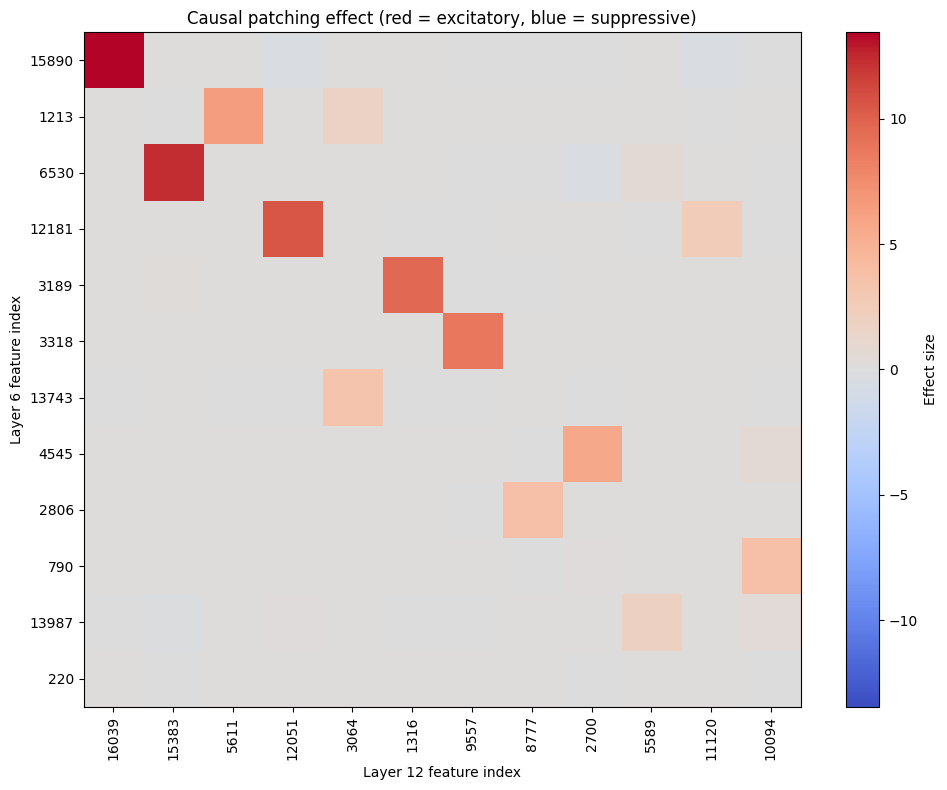

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

effect_np = effect_matrix.numpy()
max_abs = np.abs(effect_np).max() or 1.0

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(effect_np, cmap="coolwarm", vmin=-max_abs, vmax=max_abs, aspect="auto")

ax.set_xticks(range(len(late_top_idxs)))
ax.set_xticklabels([f"{idx.item()}" for idx in late_top_idxs], rotation=90)
ax.set_yticks(range(len(early_top_idxs)))
ax.set_yticklabels([f"{idx.item()}" for idx in early_top_idxs])

ax.set_xlabel(f"Layer {LATE_LAYER} feature index")
ax.set_ylabel(f"Layer {EARLY_LAYER} feature index")
ax.set_title("Causal patching effect (red = excitatory, blue = suppressive)")

fig.colorbar(im, ax=ax, label="Effect size")
plt.tight_layout()
plt.show()

In [ ]:
relative_effect = effect_matrix / late_top_vals.unsqueeze(0)  # % drop, not raw units

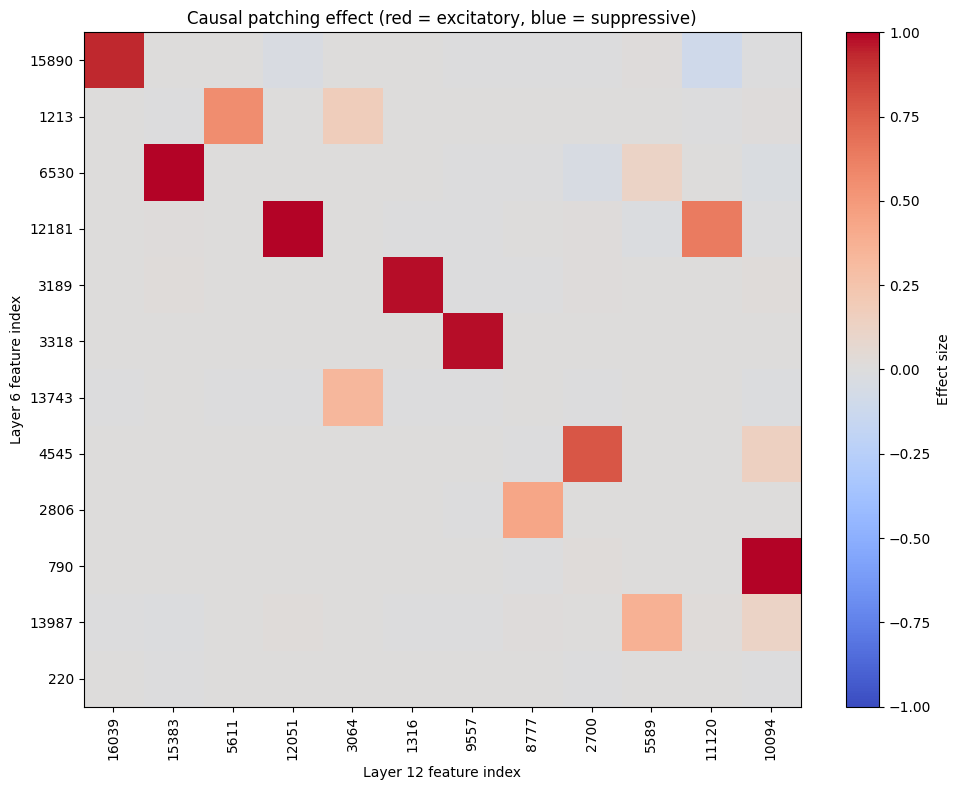

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

relative_effect_np = relative_effect.numpy()
max_abs = np.abs(relative_effect_np).max() or 1.0

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(relative_effect_np, cmap="coolwarm", vmin=-max_abs, vmax=max_abs, aspect="auto")

ax.set_xticks(range(len(late_top_idxs)))
ax.set_xticklabels([f"{idx.item()}" for idx in late_top_idxs], rotation=90)
ax.set_yticks(range(len(early_top_idxs)))
ax.set_yticklabels([f"{idx.item()}" for idx in early_top_idxs])

ax.set_xlabel(f"Layer {LATE_LAYER} feature index")
ax.set_ylabel(f"Layer {EARLY_LAYER} feature index")
ax.set_title("Relative Causal patching effect (red = excitatory, blue = suppressive)")

fig.colorbar(im, ax=ax, label="Effect size")
plt.tight_layout()
plt.show()

In [ ]:
_, cache = model.run_with_cache(
    tokens,
    names_filter=lambda name: name in (EARLY_HOOK, LATE_HOOK),
)
feats_early = sae_early.encode(cache[EARLY_HOOK]).squeeze(0)
feats_late = sae.encode(cache[LATE_HOOK]).squeeze(0)

def token_that_triggered(feature_idx, feats, label=""):
    token_pos = feats[1:, feature_idx].argmax().item() + 1
    activation_val = feats[1:, feature_idx].max().item()
    print(f"{label} feature {feature_idx}: activation {activation_val:.3f} at token {token_pos} -> '{str_tokens[token_pos]}'")

token_that_triggered(8704, feats_early, "Layer 6")
token_that_triggered(1645, feats_late, "Layer 12")

Layer 6 feature 8704: activation 0.000 at token 1 -> 'The'
Layer 12 feature 1645: activation 0.000 at token 1 -> 'The'


## Observation:
 4545 (over, pos 6) → 10094 (the, pos 7), effect 0.53

13987 (brown, pos 3) → 5589 (jumps, pos 5), effect 1.82

which inturn explained that understanding bigrams is extremely important to implement as the model probably doesn't know context awareness with respect to the word

In [ ]:
_, cache = model.run_with_cache(
    tokens,
    names_filter=lambda name: name in (EARLY_HOOK, LATE_HOOK),
)
feats_early = sae_early.encode(cache[EARLY_HOOK]).squeeze(0)
feats_late = sae.encode(cache[LATE_HOOK]).squeeze(0)

threshold = 0.5
strong_pairs = (effect_matrix.abs() > threshold).nonzero()

for i, j in strong_pairs:
    early_idx = early_top_idxs[i].item()
    late_idx = late_top_idxs[j].item()
    effect = effect_matrix[i, j].item()

    early_pos = feats_early[1:, early_idx].argmax().item() + 1
    late_pos = feats_late[1:, late_idx].argmax().item() + 1

    print(f"L6:{early_idx} (token {early_pos} '{str_tokens[early_pos]}') "
          f"-> L12:{late_idx} (token {late_pos} '{str_tokens[late_pos]}')  "
          f"effect={effect:.2f}")

L6:15890 (token 2 ' quick') -> L12:16039 (token 2 ' quick')  effect=13.44
L6:1213 (token 1 'The') -> L12:5611 (token 1 'The')  effect=6.35
L6:1213 (token 1 'The') -> L12:3064 (token 1 'The')  effect=1.72
L6:6530 (token 5 ' jumps') -> L12:15383 (token 5 ' jumps')  effect=12.31
L6:6530 (token 5 ' jumps') -> L12:5589 (token 5 ' jumps')  effect=0.59
L6:12181 (token 3 ' brown') -> L12:12051 (token 3 ' brown')  effect=10.52
L6:12181 (token 3 ' brown') -> L12:11120 (token 3 ' brown')  effect=2.45
L6:3189 (token 4 ' fox') -> L12:1316 (token 4 ' fox')  effect=9.66
L6:3318 (token 9 ' dog') -> L12:9557 (token 9 ' dog')  effect=8.73
L6:13743 (token 1 'The') -> L12:3064 (token 1 'The')  effect=3.28
L6:4545 (token 6 ' over') -> L12:2700 (token 6 ' over')  effect=5.63
L6:4545 (token 6 ' over') -> L12:10094 (token 7 ' the')  effect=0.53
L6:2806 (token 8 ' lazy') -> L12:8777 (token 8 ' lazy')  effect=3.77
L6:790 (token 7 ' the') -> L12:10094 (token 7 ' the')  effect=3.74
L6:13987 (token 3 ' brown') -> 